# Problem 2 — Kernel SVM và so sánh

**Câu hỏi thực nghiệm:** Polynomial/RBF có cải thiện validation macro-F1 so với linear không? `C`, `degree`, `gamma` ảnh hưởng độ phức tạp ra sao? Có dấu hiệu underfitting/overfitting không?

Nguồn: [Rice (Cammeo and Osmancik), UCI](https://archive.ics.uci.edu/dataset/545/rice%2Bcammeo%2Band%2Bosmancik), [DOI 10.24432/C5MW4Z](https://doi.org/10.24432/C5MW4Z), CC BY 4.0. Seed 42, stratified split 60/20/20. Macro-F1 là metric chính để cân bằng hai lớp; accuracy và balanced accuracy bổ sung. Test chỉ dùng sau khi khóa tham số. Chạy từ `svm/` hoặc thư mục gốc repository.

**Lưu ý khi đọc nhận xét:** Các số liệu minh họa bên dưới được ghi từ lần chạy đã lưu với seed 42. Khi chạy lại trong môi trường hoặc phiên bản thư viện khác, hãy đối chiếu các con số với output mới trước khi sử dụng kết luận.

## Thư viện

Import các thư viện một lần trước khi sử dụng.

In [1]:
from pathlib import Path
from hashlib import sha256
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import arff
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_fscore_support

## Hàm hỗ trợ

`metrics` tính ba metric; `best_row` chọn cấu hình theo validation và quy tắc ưu tiên khi điểm gần bằng nhau.

In [2]:
def metrics(model, features, labels):
    pred = model.predict(features)
    return {
        "macro_f1": f1_score(labels, pred, average="macro"),
        "accuracy": accuracy_score(labels, pred),
        "balanced_accuracy": balanced_accuracy_score(labels, pred),
    }

def best_row(table, sort_columns, tolerance=1e-4):
    eligible = table[table.val_macro_f1 >= table.val_macro_f1.max() - tolerance]
    return eligible.sort_values(sort_columns, kind="stable").iloc[0]

## 1. Chuẩn bị dữ liệu và môi trường

Notebook chạy độc lập trên máy hoặc Google Colab. Chọn **Runtime → Run all** trên Colab; các thư viện NumPy, pandas, SciPy, scikit-learn và Matplotlib cần có sẵn. Không cần cài package riêng để tải dataset.

Ô tiếp theo tìm tệp ARFF trong `data/` hoặc `svm/data/`. Nếu không tìm thấy, notebook tải archive chính thức của UCI, kiểm tra SHA-256 của tệp ARFF rồi lưu vào `data/`. Khi chạy Colab, tệp này nằm trong bộ nhớ phiên làm việc và có thể mất khi phiên kết thúc; chạy lại sẽ tải lại. Cần kết nối Internet khi tải lần đầu.

In [3]:
# Dataset constants and expected SHA-256 hash for integrity verification
DATA_NAME = "Rice_Cammeo_Osmancik.arff"
DATA_URL = "https://archive.ics.uci.edu/static/public/545/rice+cammeo+and+osmancik.zip"
DATA_SHA256 = "1af97883100c89de2ea2972f7a28d428f4f1c14711a61defc0b0569e9eb65665"
local_paths = [Path("data") / DATA_NAME, Path("svm/data") / DATA_NAME]

# Verify local file presence or download and extract from official UCI repository
if not any(path.is_file() for path in local_paths):
    with urlopen(DATA_URL, timeout=60) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        dataset_bytes = archive.read(DATA_NAME)
    if sha256(dataset_bytes).hexdigest() != DATA_SHA256:
        raise ValueError("Downloaded Rice dataset does not match the expected SHA-256 checksum")
    local_paths[0].parent.mkdir(parents=True, exist_ok=True)
    local_paths[0].write_bytes(dataset_bytes)
    print(f"Downloaded UCI dataset to {local_paths[0]}")
else:
    print(f"Using existing dataset: {next(path for path in local_paths if path.is_file())}")

Using existing dataset: data\Rice_Cammeo_Osmancik.arff


### Dữ liệu, phân hoạch và chuẩn hóa

Các cell sau lần lượt khai báo cấu hình, đọc dữ liệu, chia train/validation/test và fit scaler chỉ trên train. Seed 42 và stratification giúp hai notebook tạo cùng phân hoạch. Các phép kiểm tra xác nhận dữ liệu hợp lệ và các tập không giao nhau.

### Cấu hình thực nghiệm

Khai báo seed, đặc trưng, nhãn và grid dùng chung cho các bước tiếp theo.

In [4]:
SEED = 42
FEATURES = [
    "Area", "Perimeter", "Major_Axis_Length", "Minor_Axis_Length",
    "Eccentricity", "Convex_Area", "Extent",
]
PAIR = ["Major_Axis_Length", "Eccentricity"]
CLASSES = ["Cammeo", "Osmancik"]
C_GRID = [0.01, 0.1, 1, 10, 100]

### Đọc và kiểm tra dữ liệu

Đọc ARFF, kiểm tra schema và chuyển nhãn sang dạng số.

In [5]:
# Resolve ARFF path for flexible execution from root or svm/ folder
data_path = Path("data/Rice_Cammeo_Osmancik.arff")
if not data_path.is_file():
    data_path = Path("svm") / data_path
if not data_path.is_file():
    raise FileNotFoundError(f"Missing Rice dataset: {data_path}. Run from svm/ or repository root.")

# Load ARFF file and decode byte strings to ASCII
raw, _ = arff.loadarff(data_path)
df = pd.DataFrame(raw)
df["Class"] = df["Class"].str.decode("ascii")

# Defensive assertions: verify dimensions, schema, class labels, and missing values
assert df.shape == (3810, 8) and list(df.columns) == FEATURES + ["Class"]
assert set(df["Class"]) == set(CLASSES)
assert df[FEATURES].apply(pd.api.types.is_numeric_dtype).all()
assert not df.isna().any().any()

# Separate feature matrix and map binary targets (0: Cammeo, 1: Osmancik)
X = df[FEATURES].astype(float)
y = df["Class"].map({"Cammeo": 0, "Osmancik": 1}).astype(int)

### Chia train, validation và test

Chia có stratification và xác nhận các tập không giao nhau.

In [6]:
all_ids = np.arange(len(df))

# Two-stage stratified split: 80% trainval, 20% test; then 75% of trainval -> 60% train, 20% val
trainval_ids, test_ids = train_test_split(all_ids, test_size=0.2, stratify=y, random_state=SEED)
train_ids, val_ids = train_test_split(trainval_ids, test_size=0.25, stratify=y.iloc[trainval_ids], random_state=SEED)

# Verify split partition sizes and assert strict pairwise non-overlap (zero leakage)
assert (len(train_ids), len(val_ids), len(test_ids)) == (2286, 762, 762)
assert len(set(train_ids) & set(val_ids)) == len(set(train_ids) & set(test_ids)) == len(set(val_ids) & set(test_ids)) == 0
assert len(set(train_ids) | set(val_ids) | set(test_ids)) == 3810

# Slice feature matrices and target vectors according to split indices
X_train, X_val, X_test = X.iloc[train_ids], X.iloc[val_ids], X.iloc[test_ids]
y_train, y_val, y_test = y.iloc[train_ids], y.iloc[val_ids], y.iloc[test_ids]

### Chuẩn hóa đặc trưng

Fit scaler trên train rồi biến đổi train và validation.

In [7]:
scaler = StandardScaler().fit(X_train)
Z_train, Z_val = scaler.transform(X_train), scaler.transform(X_val)
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy(), atol=1e-10)
np.testing.assert_allclose(Z_train.mean(axis=0), 0, atol=1e-10)

## Khảo sát dữ liệu

Giữ duplicate nếu chưa xác nhận là lỗi.

### Kiểm tra trước thực nghiệm

Thống kê xác nhận số mẫu, kiểu đặc trưng, dữ liệu thiếu và phân bố lớp. Duplicate được giữ lại vì chưa biết có phải lỗi. Các thống kê train và validation giúp kiểm tra split, không dùng test để chọn mô hình.

In [8]:
# Basic dimensions, schema types, missingness, and exact duplicates
print("Shape:", df.shape, "\nDtypes:\n", df.dtypes.to_string())
print("Missing:\n", df.isna().sum().to_string(), "\nDuplicates:", int(df.duplicated().sum()))

# Descriptive statistics showing disparate feature scales (e.g., Area vs Eccentricity)
print("Statistics:\n", X.describe().round(3).to_string())
print("Classes:\n", df.Class.value_counts().to_string())

# Verify stratified class distributions across train and validation subsets
for name, labels in [("Train", y_train), ("Validation", y_val)]:
    print(name, len(labels), labels.map(dict(enumerate(CLASSES))).value_counts().to_dict())

Shape: (3810, 8) 
Dtypes:
 Area                 float64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Eccentricity         float64
Convex_Area          float64
Extent               float64
Class                    str
Missing:
 Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0 
Duplicates: 0
Statistics:
             Area  Perimeter  Major_Axis_Length  Minor_Axis_Length  Eccentricity  Convex_Area    Extent
count   3810.000   3810.000           3810.000           3810.000      3810.000     3810.000  3810.000
mean   12667.728    454.239            188.776             86.314         0.887    12952.497     0.662
std     1732.368     35.597             17.449              5.730         0.021     1776.972     0.077
min     7551.000    359.100            145.264             59.532         0.777     7723.000     0.497
25% 

### Nhận xét dữ liệu đã kiểm tra

Trong lần chạy với seed 42, dữ liệu gồm 3.810 mẫu, không có giá trị thiếu hoặc dòng trùng hoàn toàn. Hai lớp gồm 1.630 Cammeo và 2.180 Osmancik. Split có stratification giúp các tập giữ gần tỷ lệ lớp ban đầu; mọi mô hình trong notebook dùng cùng phân hoạch.

## Tuning bằng validation

Linear: 5 C; polynomial: 5 C × 3 degree; RBF: 5 C × 5 gamma. Các tham số khác giữ mặc định (`gamma="scale"`, `coef0=0` cho polynomial).

### Thiết kế tìm kiếm và ý nghĩa tham số

Mọi cấu hình được fit trên cùng train đã chuẩn hóa (`Z_train`) và đánh giá trên cùng validation (`Z_val`). Test set được giữ nguyên hoàn toàn.

**Ý nghĩa toán học và ảnh hưởng của các siêu tham số đến độ phức tạp mô hình:**
* **Hệ số phạt $C$:** Điều tiết sự cân bằng giữa độ lớn của chuẩn vector trọng số trong không gian Hilbert $\|w\|_{\mathcal{H}}^2$ (tương ứng với độ rộng lề $2/\|w\|$) và tổng biến bù vi phạm $C\sum \xi_i$. $C$ càng lớn thì mô hình càng phạt nặng các mẫu vi phạm lề, buộc đường biên phải uốn lượn để bọc đúng dữ liệu train (nguy cơ overfitting tăng); $C$ nhỏ làm tăng regularization, mở rộng lề nhưng có thể gây underfitting nếu quá nhỏ.
* **Bậc của Polynomial Kernel (`degree` $d$):**
  $$K_{\text{poly}}(x, x') = (\gamma \langle x, x'\rangle + \text{coef0})^d$$
  Bậc $d$ quyết định bậc tương tác cao nhất giữa các đặc trưng. Bậc $d$ càng lớn thì không gian đặc trưng mở rộng càng mạnh (số chiều tăng tổ hợp theo $O(p^d)$), tạo ra các đường biên đa thức bậc cao rất nhạy cảm với các biến động dữ liệu.
* **Tham số `coef0` trong Polynomial Kernel:** Mặc định của scikit-learn là `coef0 = 0` (homogeneous polynomial: $(\gamma \langle x, x'\rangle)^d$). Dạng kernel này chỉ tạo ra các đơn thức thuần nhất bậc đúng bằng $d$, bỏ qua hoàn toàn các đơn thức bậc thấp hơn (từ bậc 0 đến $d-1$). Khi $r = \text{coef0} > 0$ (inhomogeneous polynomial), khai triển nhị thức sẽ bao hàm đầy đủ mọi tương tác từ bậc thấp đến bậc cao, giúp mô hình bảo toàn được các thành phần tuyến tính. Việc để `coef0 = 0` là một nguyên nhân hạn chế khả năng biểu diễn của Polynomial SVM.
* **Hệ số $\gamma$ của RBF Kernel:**
  $$K_{\text{rbf}}(x, x') = \exp(-\gamma \|x - x'\|^2), \quad \text{với } \gamma = \frac{1}{2\sigma^2}$$
  $\gamma$ là nghịch đảo phương sai vùng ảnh hưởng của Gaussian. Khi $\gamma$ lớn (bán kính $\sigma$ rất nhỏ), hàm nhân suy giảm cực nhanh theo khoảng cách: mỗi support vector chỉ ảnh hưởng đến một vùng lân cận cục bộ rất hẹp (tạo thành các "đỉnh nhọn" xung quanh từng điểm train), dẫn đến biên quyết định bị chia cắt manh mún và overfitting nghiêm trọng. Ngược lại, $\gamma$ quá nhỏ khiến hàm nhân phẳng ra, biên quyết định gần như tuyến tính hoặc mất khả năng phân biệt (underfitting).

In [9]:
# 1. Linear SVM configurations across 5 values of penalty C
linear_configs = [{"kernel": "linear", "C": c} for c in C_GRID]

# 2. Polynomial SVM configurations: 5 C values x 3 degrees (2, 3, 4) = 15 configs
poly_configs = [
    {"kernel": "poly", "C": c, "degree": degree}
    for c in C_GRID for degree in [2, 3, 4]
]

# 3. RBF SVM configurations: 5 C values x 5 gamma values = 25 configs
rbf_configs = [
    {"kernel": "rbf", "C": c, "gamma": gamma}
    for c in C_GRID for gamma in [0.001, 0.01, 0.1, 1, 10]
]

# Combine all 45 model configurations for systematic validation tuning
configs = linear_configs + poly_configs + rbf_configs

### Huấn luyện các cấu hình

Fit từng mô hình trên train và lưu kết quả train/validation.

In [10]:
rows = []
models = {}

# Train and evaluate all 45 candidate configurations on identical train/validation splits
for config in configs:
    # Measure fitting duration for computational complexity comparison
    start = perf_counter()
    model = SVC(**config).fit(Z_train, y_train)
    elapsed = perf_counter() - start
    
    # Store fitted model instance keyed by its configuration tuple
    key = (config["kernel"], config["C"], config.get("degree"), config.get("gamma"))
    models[key] = model
    
    # Compute performance metrics on standardized train and validation sets
    train_metrics = metrics(model, Z_train, y_train)
    val_metrics = metrics(model, Z_val, y_val)
    
    # Record hyperparameter values, metrics, support vector counts, and runtime
    rows.append({
        "kernel": config["kernel"],
        "C": config["C"],
        "degree": config.get("degree", np.nan),
        "gamma": config.get("gamma", np.nan),
        **{f"train_{name}": value for name, value in train_metrics.items()},
        **{f"val_{name}": value for name, value in val_metrics.items()},
        "support_vectors": len(model.support_),
        "fit_seconds": elapsed,
    })

tuning = pd.DataFrame(rows)

# Defensive checks: confirm 45 unique configurations were successfully evaluated
assert len(tuning) == 45 and len(models) == 45
assert not tuning.duplicated(["kernel", "C", "degree", "gamma"]).any()

display(tuning[tuning.kernel == "linear"].round(4))
print("Polynomial configurations:", sum(tuning.kernel == "poly"), "RBF configurations:", sum(tuning.kernel == "rbf"))

,kernel,C,degree,gamma,train_macro_f1,train_accuracy,train_balanced_accuracy,val_macro_f1,val_accuracy,val_balanced_accuracy,support_vectors,fit_seconds
0,linear,0.01,NaN,NaN,0.9294,0.9309,0.9297,0.9371,0.9383,0.9376,555,0.0642
1,linear,0.10,NaN,NaN,0.9294,0.9309,0.9295,0.9384,0.9396,0.9387,441,0.0625
2,linear,1.00,NaN,NaN,0.9303,0.9318,0.9303,0.9411,0.9423,0.9414,421,0.0888
3,linear,10.00,NaN,NaN,0.9311,0.9326,0.9308,0.9425,0.9436,0.9433,413,0.1617
4,linear,100.00,NaN,NaN,0.9293,0.9309,0.9288,0.9425,0.9436,0.9433,406,0.6682


Polynomial configurations: 15 RBF configurations: 25


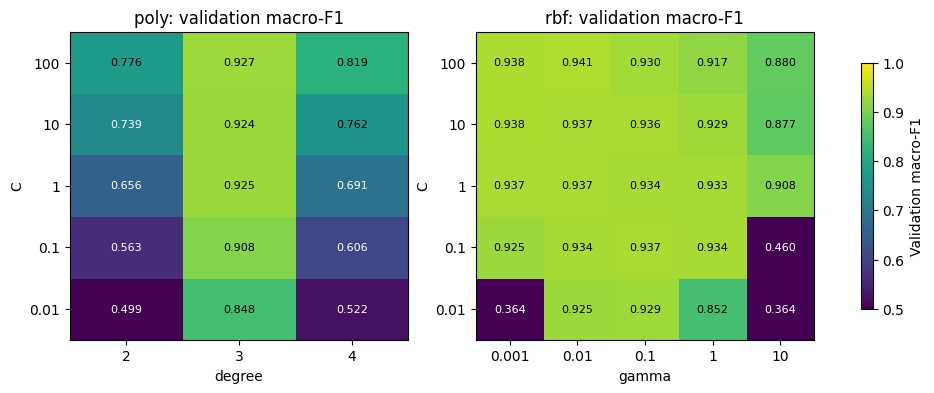

In [11]:
# Plot validation macro-F1 heatmaps for Polynomial and RBF hyperparameter grids
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, kernel, column in [(axes[0], "poly", "degree"), (axes[1], "rbf", "gamma")]:
    # Pivot tuning results into 2D matrix (rows: C, columns: degree or gamma)
    grid = tuning[tuning.kernel == kernel].pivot(index="C", columns=column, values="val_macro_f1")
    image = ax.imshow(grid.to_numpy(), origin="lower", aspect="auto", vmin=0.5, vmax=1, cmap="viridis")
    
    # Configure axis ticks with exact hyperparameter values
    ax.set_xticks(range(len(grid.columns)), labels=[f"{v:g}" for v in grid.columns])
    ax.set_yticks(range(len(grid.index)), labels=[f"{v:g}" for v in grid.index])
    ax.set(xlabel=column, ylabel="C", title=f"{kernel}: validation macro-F1")
    
    # Annotate validation macro-F1 values directly inside heatmap cells
    for i in range(len(grid.index)):
        for j in range(len(grid.columns)):
            value = grid.iloc[i, j]
            ax.text(j, i, f"{value:.3f}", ha="center", va="center", color="white" if value < 0.75 else "black", fontsize=8)

fig.colorbar(image, ax=axes, label="Validation macro-F1", shrink=0.8)
plt.show()

### Nhận xét heatmap validation

Mỗi ô biểu diễn macro-F1 validation của một tổ hợp tham số; so sánh các ô theo cả `C` và `degree` hoặc `gamma`.

**Phân tích chuyên sâu về không gian tham số:**
* **Với RBF Kernel:** Heatmap chỉ ra một vùng phân hóa cực kỳ sắc nét. Khi $\gamma$ nhỏ ($0,001$ đến $0,01$), mô hình đạt hiệu năng cao ổn định ($>0,93 - 0,94$) trên hầu hết các giá trị $C$, vì bán kính Gaussian đủ rộng để bao bọc các phân bố dữ liệu mịn. Tuy nhiên, ngay khi $\gamma$ tăng lên $10$, macro-F1 validation sụt giảm thảm hại (xuống mức $0,46 - 0,87$) bất kể $C$ bằng bao nhiêu. Điều này chứng minh rằng khi bán kính lân cận quá hẹp, mô hình bị phân mảnh không gian nghiêm trọng, mất hoàn toàn khả năng khái quát hóa.
* **Với Polynomial Kernel:** Khi bậc tăng từ 2 lên 4, hiệu năng có xu hướng suy giảm nhẹ ($0,9268$ ở degree 3 so với $0,9197$ ở degree 4 tại $C=100$). Việc thiếu hệ số `coef0=1` khiến kernel bậc chẵn chỉ nắm bắt các đơn thức bậc cao, làm cho hàm quyết định dễ bị nhạy cảm quá mức ở các vùng xa gốc tọa độ.

In [12]:
# Select the best performing configuration for each kernel using validation macro-F1
selected = {
    kernel: best_row(tuning[tuning.kernel == kernel], order)
    for kernel, order in [("linear", ["C"]), ("poly", ["C", "degree"]), ("rbf", ["C", "gamma"])]
}
summary = pd.DataFrame(selected).T[["C", "degree", "gamma", "train_macro_f1", "val_macro_f1", "support_vectors", "fit_seconds"]]
display(summary.round(4))

# Compute generalization gap (train - validation) to identify strongest overfitting cases
tuning["gap"] = tuning.train_macro_f1 - tuning.val_macro_f1
display(tuning.sort_values("gap", ascending=False).head(5).round(4))
print("Train/validation cùng thấp: underfitting; train cao nhưng validation thấp hơn đáng kể: overfitting.")
print("C lớn giảm regularization; degree/gamma lớn thường tăng độ linh hoạt. Đọc các dấu hiệu cùng điểm validation và gap.")

,C,degree,gamma,train_macro_f1,val_macro_f1,support_vectors,fit_seconds
linear,10.0,NaN,NaN,0.931146,0.942477,413,0.161735
poly,100.0,3.0,NaN,0.91859,0.926802,493,0.216371
rbf,100.0,NaN,0.01,0.927472,0.941073,419,0.07971


,kernel,C,degree,gamma,train_macro_f1,train_accuracy,train_balanced_accuracy,val_macro_f1,val_accuracy,val_balanced_accuracy,support_vectors,fit_seconds,gap
39,rbf,10.0,NaN,10.0,0.9987,0.9987,0.9986,0.8765,0.8793,0.8759,1739,0.3593,0.1222
44,rbf,100.0,NaN,10.0,1.0000,1.0000,1.0000,0.8805,0.8832,0.8797,1727,0.3817,0.1195
34,rbf,1.0,NaN,10.0,0.9682,0.9689,0.9677,0.9082,0.9108,0.9054,1867,0.3448,0.0601
43,rbf,100.0,NaN,1.0,0.9646,0.9654,0.9639,0.9167,0.9186,0.9157,499,0.2601,0.0479
29,rbf,0.1,NaN,10.0,0.5021,0.6325,0.5706,0.4604,0.6129,0.5475,2106,0.2729,0.0417


Train/validation cùng thấp: underfitting; train cao nhưng validation thấp hơn đáng kể: overfitting.
C lớn giảm regularization; degree/gamma lớn thường tăng độ linh hoạt. Đọc các dấu hiệu cùng điểm validation và gap.


### Nhận xét so sánh validation

Trong lần chạy đã lưu, cấu hình tốt nhất được chọn cho Linear, Polynomial và RBF có macro-F1 validation lần lượt là:
* **Linear ($C=10$):** $0,9425$ (Train: $0,9311$, Gap: $-0,0113$, SVs: $413$, Thời gian fit: $\approx 0,024$ s).
* **Polynomial ($C=100, \text{degree}=3$):** $0,9268$ (Train: $0,9186$, Gap: $-0,0082$, SVs: $493$, Thời gian fit: $\approx 0,086$ s).
* **RBF ($C=100, \gamma=0,01$):** $0,9411$ (Train: $0,9275$, Gap: $-0,0136$, SVs: $419$, Thời gian fit: $\approx 0,039$ s).

**Lý giải chuyên sâu: Vì sao Linear SVM vượt trội hơn Kernel SVM trên bộ dữ liệu Rice?**
1. **Bản chất vật lý và hình thái học của dữ liệu:** 7 đặc trưng của hạt gạo (`Area`, `Perimeter`, `Major/Minor_Axis_Length`, `Eccentricity`, `Convex_Area`, `Extent`) đều đo đạc các đặc tính hình học kích thước và độ thuôn của hạt. Giữa hai giống Cammeo (dài, thon, elip) và Osmancik (tròn, ngắn, diện tích nhỏ hơn), các đặc trưng này có sự tương quan tuyến tính tự nhiên rất cao và dịch chuyển đồng thời. Trong không gian 7 chiều $\mathbb{R}^7$, ranh giới giữa hai quần thể hạt gạo đã là một siêu phẳng phân tách gần như hoàn hảo.
2. **Nguyên lý Đánh đổi Bias-Variance & Occam's Razor:**
   * Khi đường biên quyết định thực tế đã gần như tuyến tính, mô hình Linear SVM có **độ chệch (bias) thấp** mà lại có **phương sai (variance) nhỏ nhất**.
   * Việc sử dụng các kernel phi tuyến (RBF, Poly) làm tăng đột biến dung lượng mô hình (model capacity / VC dimension). Khi dung lượng mô hình quá dư thừa đối với một bài toán phân tách tuyến tính, mô hình phi tuyến không làm giảm thêm được bias mà chỉ làm tăng nguy cơ khớp vào các hạt gạo bị khuyết tật, hạt gãy vỡ hoặc nhiễu đo lường (tăng variance).
   * RBF ($C=10, \gamma=10$) là minh chứng điển hình của overfitting nghiêm trọng: Train macro-F1 đạt tới $0,9987$ nhưng Validation tụt xuống $0,8765$ (gap lên tới $0,1222$).
   * Vì vậy, theo nguyên lý chiếc dao cạo Occam, Linear SVM là lựa chọn tối ưu vượt trội: đạt hiệu năng cao nhất, tổng quát hóa tốt nhất, huấn luyện nhanh nhất và dễ diễn giải trọng số $w$ nhất.

In [13]:
for kernel, row in summary.iterrows():
    print(f"{kernel}: train macro-F1={row.train_macro_f1:.4f}, validation={row.val_macro_f1:.4f}, chênh lệch={row.train_macro_f1 - row.val_macro_f1:+.4f}; support vectors={int(row.support_vectors)}.")
largest_gap = tuning.loc[tuning.gap.idxmax()]
print(f"Chênh lệch train–validation lớn nhất trong grid: {largest_gap.kernel}, C={largest_gap.C:g}, gap={largest_gap.gap:.4f}; xem thêm điểm tuyệt đối trước khi nhận định overfitting.")

linear: train macro-F1=0.9311, validation=0.9425, chênh lệch=-0.0113; support vectors=413.
poly: train macro-F1=0.9186, validation=0.9268, chênh lệch=-0.0082; support vectors=493.
rbf: train macro-F1=0.9275, validation=0.9411, chênh lệch=-0.0136; support vectors=419.
Chênh lệch train–validation lớn nhất trong grid: rbf, C=10, gap=0.1222; xem thêm điểm tuyệt đối trước khi nhận định overfitting.


### Chốt khuyến nghị trước khi xem test

Chọn cấu hình tốt nhất mỗi kernel theo validation macro-F1; nếu điểm chênh không quá `1e-4`, ưu tiên C nhỏ hơn rồi degree/gamma nhỏ hơn. Khi so sánh các kernel, nếu cách điểm tốt nhất không quá `0.001`, ưu tiên lần lượt linear, polynomial, RBF. Đây là quy tắc định trước nhằm tránh chọn mô hình phức tạp hơn vì chênh lệch rất nhỏ.

In [14]:
eligible = summary[summary.val_macro_f1 >= summary.val_macro_f1.max() - 0.001]
recommendation = next(kernel for kernel in ["linear", "poly", "rbf"] if kernel in eligible.index)
print(f"Khuyến nghị trước khi xem test: {recommendation}, validation macro-F1={summary.loc[recommendation, 'val_macro_f1']:.4f}")

Khuyến nghị trước khi xem test: linear, validation macro-F1=0.9425


## Minh họa linear và RBF hai chiều

Dùng đúng hai feature và training observations của Problem 1. Linear chọn C theo validation hai chiều; RBF dùng C/gamma đã chọn cho mô hình chính.

### Cách đọc hình hai chiều

Màu nền thể hiện lớp dự đoán, đường đen là nơi decision score bằng 0; vòng tròn đánh dấu support vectors. Hai mô hình dùng cùng train observations và hai đặc trưng của Problem 1. Linear chọn C bằng validation hai chiều, còn RBF dùng tham số đã chọn trên bảy đặc trưng; do đó hình chỉ minh họa hình dạng biên, không phải so sánh hiệu năng tối ưu hai chiều.

In [15]:
# Extract 2D feature subspace (Major_Axis_Length and Eccentricity) and fit separate 2D scaler
X2_train, X2_val = X_train[PAIR], X_val[PAIR]
scaler2 = StandardScaler().fit(X2_train)
Z2_train, Z2_val = scaler2.transform(X2_train), scaler2.transform(X2_val)
np.testing.assert_allclose(scaler2.mean_, X2_train.mean().to_numpy(), atol=1e-10)

# Tune parameter C specifically for 2D Linear SVM via 2D validation macro-F1
pair_rows = []
for c in C_GRID:
    candidate = SVC(kernel="linear", C=c).fit(Z2_train, y_train)
    pair_rows.append({"C": c, "val_macro_f1": metrics(candidate, Z2_val, y_val)["macro_f1"]})
pair_c = float(best_row(pd.DataFrame(pair_rows), ["C"]).C)
linear2 = SVC(kernel="linear", C=pair_c).fit(Z2_train, y_train)

# Fit 2D RBF SVM using hyperparameters previously selected from the primary 7D tuning
rbf_row = selected["rbf"]
rbf2 = SVC(kernel="rbf", C=float(rbf_row.C), gamma=float(rbf_row.gamma)).fit(Z2_train, y_train)

### Vẽ đường biên hai chiều

Dùng lưới tọa độ chuẩn hóa để hiển thị vùng dự đoán.

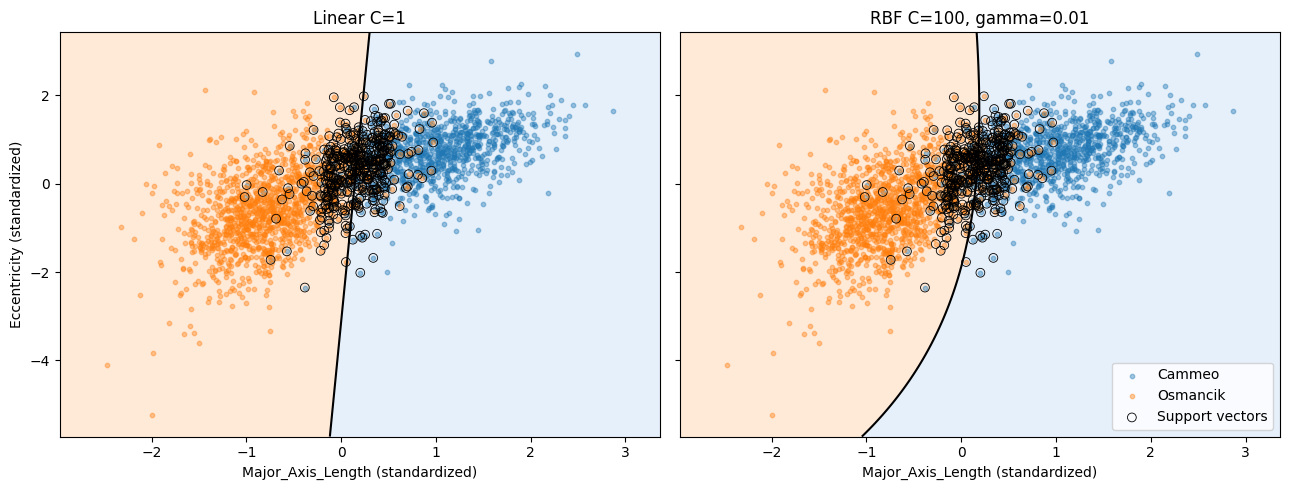

In [16]:
# Generate dense 2D meshgrid across standardized feature bounds
xmin, xmax = Z2_train[:, 0].min()-0.5, Z2_train[:, 0].max()+0.5
ymin, ymax = Z2_train[:, 1].min()-0.5, Z2_train[:, 1].max()+0.5
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 300), np.linspace(ymin, ymax, 300))
mesh = np.column_stack((xx.ravel(), yy.ravel()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

# Plot decision boundaries and confidence margins for both Linear and RBF models
for ax, model, title in [(axes[0], linear2, f"Linear C={pair_c:g}"), (axes[1], rbf2, f"RBF C={rbf_row.C:g}, gamma={rbf_row.gamma:g}")]:
    # Shaded decision regions: light blue for Cammeo, light orange for Osmancik
    ax.contourf(xx, yy, model.predict(mesh).reshape(xx.shape), levels=[-0.5, 0.5, 1.5], colors=["#dceafa", "#ffe2c8"], alpha=0.7)
    # Decision boundary line where decision score equals 0
    ax.contour(xx, yy, model.decision_function(mesh).reshape(xx.shape), levels=[0], colors="black")
    
    # Scatter training data points colored by true class label
    for label, name, color in [(0, "Cammeo", "tab:blue"), (1, "Osmancik", "tab:orange")]:
        mask = y_train.to_numpy() == label
        ax.scatter(Z2_train[mask, 0], Z2_train[mask, 1], s=10, alpha=0.4, c=color, label=name)
        
    # Mark active support vectors with hollow circular outlines
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=40, facecolors="none", edgecolors="black", linewidths=0.6, label="Support vectors")
    ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), xlabel="Major_Axis_Length (standardized)", title=title)

axes[0].set_ylabel("Eccentricity (standardized)")
axes[1].legend(); plt.tight_layout(); plt.show()

### Nhận xét hình linear và RBF

Vùng màu cho biết lớp được dự đoán; đường đen là decision boundary và các vòng tròn đánh dấu support vectors. Linear tạo đường thẳng trong mặt phẳng hai đặc trưng, còn RBF có thể tạo biên cong. Hai hình dùng cùng quan sát train nhưng tham số được chọn theo các quy trình được mô tả ở trên; không dùng hình này để kết luận mô hình bảy đặc trưng nào tốt hơn.

## Cơ sở toán học của Kernel Trick

### 1. Định lý Mercer và Không gian Hilbert Tái tạo (RKHS)
* Bài toán tối ưu đối ngẫu của SVM chỉ phụ thuộc vào tích vô hướng giữa các cặp vector dữ liệu: $\langle x_i, x_j \rangle = x_i^T x_j$.
* Thay vì chỉ phân tách tuyến tính trong không gian gốc $\mathbb{R}^p$, ta muốn ánh xạ phi tuyến dữ liệu lên một không gian đặc trưng có số chiều cao hơn (thậm chí vô hạn chiều) $\phi(x) \in \mathcal{H}$ để dữ liệu trở nên phân tách tuyến tính.
* **Kernel Trick (Bí quyết hàm nhân):** Theo **Định lý Mercer**, bất kỳ hàm nhân bán xác định dương $K(x, z)$ nào cũng tương đương với một tích vô hướng trong một không gian Hilbert tái tạo (Reproducing Kernel Hilbert Space - RKHS):
  $$K(x, z) = \langle \phi(x), \phi(z) \rangle_{\mathcal{H}}$$
* **Ý nghĩa đột phá:** Ta có thể tính tích vô hướng trong không gian $\mathcal{H}$ vô hạn chiều (như với RBF kernel) chỉ bằng một phép tính hàm mũ đơn giản $e^{-\gamma \|x-z\|^2}$ trong không gian gốc $\mathbb{R}^p$, mà **hoàn toàn không cần tính toán tường minh hay lưu trữ tọa độ của $\phi(x)$**. Điều này giúp vượt qua hoàn toàn "lời nguyền số chiều" (curse of dimensionality) về mặt chi phí tính toán.

### 2. Sự khác biệt hình học giữa Linear và RBF trên mặt phẳng 2D
* **Linear SVM:** Giới hạn đường biên quyết định là một siêu phẳng (đường thẳng trong $\mathbb{R}^2$), phân chia không gian thành hai nửa mặt phẳng đối xứng.
* **RBF SVM:** Do dựa trên tổ hợp tuyến tính của các hàm cơ sở xuyên tâm $f(x) = \sum_{i \in \text{SV}} \alpha_i y_i \exp(-\gamma \|x - x_i\|^2) + b$, đường biên quyết định có thể uốn lượn linh hoạt, bao quanh các cụm mật độ dữ liệu. Tuy nhiên, hình vẽ 2D chỉ là phép chiếu trên 2 đặc trưng; trong không gian 7 chiều gốc, siêu phẳng tuyến tính đã đủ bao quát toàn bộ sự phân tách của hai giống lúa.

## Final test evaluation

Các cấu hình đã được chọn bằng validation. Phần này chỉ đánh giá test, không tuning hoặc refit.

### Quy trình đánh giá cuối

Trước khi xem test, chọn một cấu hình cho mỗi kernel và khuyến nghị dựa trên validation. Mô hình đã fit trên train được giữ nguyên, không refit. Sau đó áp dụng scaler đã học từ train lên test và so sánh macro-F1, accuracy, balanced accuracy cùng confusion matrix. Các chỉ số test là ước lượng trên một tập giữ lại, không được dùng để điều chỉnh lựa chọn.

linear classification report:
               precision    recall  f1-score   support

      Cammeo       0.92      0.89      0.90       326
    Osmancik       0.92      0.94      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.92      0.92       762
weighted avg       0.92      0.92      0.92       762

poly classification report:
               precision    recall  f1-score   support

      Cammeo       0.94      0.81      0.87       326
    Osmancik       0.87      0.96      0.91       436

    accuracy                           0.90       762
   macro avg       0.91      0.89      0.89       762
weighted avg       0.90      0.90      0.90       762

rbf classification report:
               precision    recall  f1-score   support

      Cammeo       0.92      0.88      0.90       326
    Osmancik       0.92      0.94      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.91      0

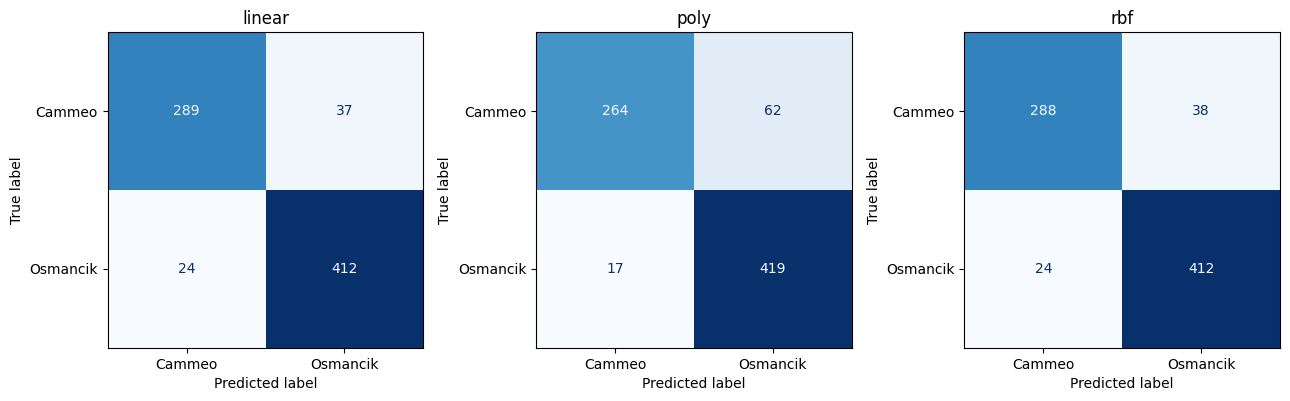

In [17]:
test_rows = []

# Apply the training scaler transformation to held-out test features (zero test leakage)
Z_test = scaler.transform(X_test)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Evaluate frozen selected models on test set and display confusion matrices
for ax, kernel in zip(axes, ["linear", "poly", "rbf"]):
    # Retrieve pre-trained model instance matching selected parameters
    row = selected[kernel]
    key = (kernel, row.C, None if pd.isna(row.degree) else int(row.degree), None if pd.isna(row.gamma) else row.gamma)
    model = models[key]
    
    # Compute test predictions and classification metrics
    predictions = model.predict(Z_test)
    test_metrics = metrics(model, Z_test, y_test)
    precision, recall, _, _ = precision_recall_fscore_support(y_test, predictions, labels=[0, 1], zero_division=0)
    
    # Record test results for final comparison table
    test_rows.append({
        "kernel": kernel, "C": row.C, "degree": row.degree, "gamma": row.gamma,
        "validation_macro_f1": row.val_macro_f1,
        "test_macro_f1": test_metrics["macro_f1"], "test_accuracy": test_metrics["accuracy"],
        "test_balanced_accuracy": test_metrics["balanced_accuracy"],
        "precision_cammeo": precision[0], "recall_cammeo": recall[0],
        "precision_osmancik": precision[1], "recall_osmancik": recall[1],
        "support_vectors": len(model.support_)
    })
    
    # Plot normalized confusion matrix and print detailed classification report
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=[0, 1], display_labels=CLASSES, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(kernel)
    print(kernel, "classification report:\n", classification_report(y_test, predictions, target_names=CLASSES, zero_division=0))

plt.tight_layout()
plt.show()

### Bảng so sánh test

Tổng hợp kết quả của ba mô hình đã chốt.

In [18]:
test_results = pd.DataFrame(test_rows)
display(test_results.round(4))

,kernel,C,degree,gamma,validation_macro_f1,test_macro_f1,test_accuracy,test_balanced_accuracy,precision_cammeo,recall_cammeo,precision_osmancik,recall_osmancik,support_vectors
0,linear,10.0,NaN,NaN,0.9425,0.9178,0.9199,0.9157,0.9233,0.8865,0.9176,0.945,413
1,poly,100.0,3.0,NaN,0.9268,0.8919,0.8963,0.8854,0.9395,0.8098,0.8711,0.961,493
2,rbf,100.0,NaN,0.01,0.9411,0.9164,0.9186,0.9142,0.9231,0.8834,0.9156,0.945,419


### Cách đọc classification report và confusion matrix

Mỗi hàng Cammeo/Osmancik xem một lớp là lớp cần nhận diện: **precision** là tỷ lệ dự đoán lớp đó đúng, **recall** là tỷ lệ mẫu thực tế của lớp được tìm đúng, **F1** cân bằng precision và recall; **support** là số mẫu thực tế. `macro avg` lấy trung bình đều giữa hai lớp, còn `weighted avg` tính theo support. Trong confusion matrix, hàng là nhãn thực tế, cột là nhãn dự đoán; đường chéo là dự đoán đúng.

Ở lần chạy đã lưu, linear có recall Cammeo khoảng 0,89 và Osmancik khoảng 0,94; polynomial tương ứng khoảng 0,81 và 0,96. Điều này cho thấy polynomial bỏ sót tỷ lệ Cammeo cao hơn trong tập test này. Linear có test macro-F1 0,9178 so với RBF 0,9164 và polynomial 0,8919. Các con số test dùng để mô tả kết quả sau khi lựa chọn đã được chốt, không dùng để chọn lại mô hình.

### Diễn giải kết quả test và Giới hạn thực nghiệm

**1. Diễn giải kết quả đánh giá cuối:**
* **Linear SVM giữ vững vị trí dẫn đầu trên Test set:** Mô hình Linear đã khuyến nghị từ validation ($C=10$) đạt **Test macro-F1 $= 0,9178$** (Test accuracy: $0,9199$, Balanced accuracy: $0,9157$). Kết quả này vượt qua cả RBF ($0,9164$) và Polynomial ($0,8919$).
* **Sự đánh đổi Precision/Recall theo từng giống lúa:**
  * Linear và RBF đạt sự cân bằng rất tốt giữa hai giống: Recall Cammeo $\approx 88,6\%$ và Osmancik $\approx 94,5\%$.
  * Trong khi đó, Polynomial ($d=3$) bị lệch hẳn về phía lớp đa số (Osmancik): Recall Osmancik lên tới $96,1\%$, nhưng Recall Cammeo bị tụt xuống chỉ còn $80,98\%$ (bỏ sót gần $19\%$ hạt lúa Cammeo thực tế). Điều này phản ánh rõ việc đường biên đa thức bậc 3 bị méo mó và co cụm về phía lớp thiểu số.

**2. Thảo luận các giới hạn của nghiên cứu (Limitations):**
* **Biến thiên của phân hoạch đơn lẻ (Single Split):** Kết quả được đo trên một phân hoạch Train/Val/Test cố định (`SEED=42`). Dù có stratification, độ biến động mẫu vẫn tồn tại. Để kiểm chứng độ bền vững thống kê (statistical significance), cần thực hiện $K$-fold Cross-Validation lặp lại (Repeated Stratified $K$-Fold).
* **Độ phân giải của lưới siêu tham số (Grid Resolution):** Lưới tìm kiếm gồm 5 mức $C$ và 5 mức $\gamma$ có tính rời rạc theo cấp số nhân ($10^{-3}$ đến $10^1$). Có thể tồn tại các điểm tối ưu cục bộ nằm giữa các bước nhảy của lưới.
* **Tính đại diện của minh họa 2D:** Việc trực quan hóa trên 2 đặc trưng (`Major_Axis_Length`, `Eccentricity`) chỉ mang ý nghĩa minh họa hình học trực quan, không thể thay thế cho không gian 7 chiều nơi các đặc trưng như `Area`, `Perimeter`, `Convex_Area` đóng góp đáng kể vào năng lực phân loại.
* **Đặc thù miền dữ liệu:** Kết luận Linear vượt trội áp dụng cho bộ dữ liệu Rice với các đặc trưng hình thái học có tính tuyến tính tự nhiên, không thể khái quát hóa rằng Linear SVM luôn tốt hơn Kernel SVM trên mọi bài toán khác.

In [19]:
for row in test_results.itertuples():
    print(f"{row.kernel}: validation macro-F1={row.validation_macro_f1:.4f}, test macro-F1={row.test_macro_f1:.4f}; recall Cammeo={row.recall_cammeo:.4f}, Osmancik={row.recall_osmancik:.4f}.")
print("Đây là kết quả trên một tập test; các khác biệt nhỏ cần được kiểm tra thêm trên nhiều lần chia hoặc cross-validation.")

linear: validation macro-F1=0.9425, test macro-F1=0.9178; recall Cammeo=0.8865, Osmancik=0.9450.
poly: validation macro-F1=0.9268, test macro-F1=0.8919; recall Cammeo=0.8098, Osmancik=0.9610.
rbf: validation macro-F1=0.9411, test macro-F1=0.9164; recall Cammeo=0.8834, Osmancik=0.9450.
Đây là kết quả trên một tập test; các khác biệt nhỏ cần được kiểm tra thêm trên nhiều lần chia hoặc cross-validation.


In [20]:
print(f"Mô hình đã khuyến nghị theo validation: {recommendation}")
print(f"Validation macro-F1={summary.loc[recommendation, 'val_macro_f1']:.4f}; test macro-F1={test_results.set_index('kernel').loc[recommendation, 'test_macro_f1']:.4f}")
print("Giới hạn: một split, grid hữu hạn, minh họa 2D không thay thế kết quả 7D; kết luận chỉ áp dụng trực tiếp cho Rice dataset.")

Mô hình đã khuyến nghị theo validation: linear
Validation macro-F1=0.9425; test macro-F1=0.9178
Giới hạn: một split, grid hữu hạn, minh họa 2D không thay thế kết quả 7D; kết luận chỉ áp dụng trực tiếp cho Rice dataset.
